In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset saved after EDA.
df = pd.read_csv(
    r"C:\Users\rajab\Desktop\ML-Health-Insurance\ML-Health-Insurance\main\cleaned.csv"
)

# Preserve an unchanged copy.
original_df = df.copy(deep=True)

print("Dataset shape:", df.shape)

print("\nObservations by year:")
print(df["period"].value_counts().sort_index())

display(df.head())

Dataset shape: (162629, 42)

Observations by year:
period
2017    55999
2018    53555
2019    53075
Name: count, dtype: int64


C:\Users\rajab\AppData\Local\Temp\ipykernel_30856\3232678886.py:7: DtypeWarning: Columns (5: date_lapse_insured, 7: date_lapse_policy) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


,ID,ID_policy,ID_insured,period,date_effect_insured,date_lapse_insured,date_effect_policy,date_lapse_policy,year_effect_insured,year_lapse_insured,...,C_H,C_GI,C_II,C_IE_P,C_IE_S,C_IE_T,C_GE_P,C_GE_S,C_GE_T,C_C
0,1_2,1,2,2017,1993-06-15,NaN,1993-06-15,NaN,1993,NaN,...,H1,99.0,85.0,18.0,52.0,59.0,4.0,14.0,96.0,C6
1,2_1,2,1,2017,1993-06-16,NaN,1993-06-16,NaN,1993,NaN,...,H6,100.0,94.0,26.0,11.0,85.0,7.0,1.0,100.0,C6
2,3_3,3,3,2017,1993-06-15,NaN,1993-06-15,NaN,1993,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3_5,3,5,2017,1993-06-15,NaN,1993-06-15,NaN,1993,NaN,...,H6,99.0,81.0,32.0,34.0,69.0,9.0,4.0,98.0,C6
4,3_6,3,6,2017,1993-06-15,NaN,1993-06-15,NaN,1993,NaN,...,H1,32.0,9.0,100.0,80.0,2.0,83.0,51.0,19.0,C4


In [2]:
df.columns

Index(['ID', 'ID_policy', 'ID_insured', 'period', 'date_effect_insured',
       'date_lapse_insured', 'date_effect_policy', 'date_lapse_policy',
       'year_effect_insured', 'year_lapse_insured', 'year_effect_policy',
       'year_lapse_policy', 'exposure_time', 'lapse', 'seniority_insured',
       'seniority_policy', 'type_policy', 'type_policy_dg', 'type_product',
       'reimbursement', 'new_business', 'distribution_channel', 'gender',
       'age', 'premium', 'cost_claims_year', 'n_medical_services',
       'n_insured_pc', 'n_insured_mun', 'n_insured_prov', 'IICIMUN',
       'IICIPROV', 'C_H', 'C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T',
       'C_GE_P', 'C_GE_S', 'C_GE_T', 'C_C'],
      dtype='str')

In [3]:
# Identify chronologically inconsistent observations.
invalid_rows = (
    df["seniority_insured"] - df["age"] > 1
)

print("Observations to remove:", invalid_rows.sum())

print("\nRemovals by year:")
print(df.loc[invalid_rows, "period"].value_counts().sort_index())

# Remove the flagged observations.
df = df.loc[~invalid_rows].copy()

print("\nRemaining dataset shape:", df.shape)

print("\nRemaining observations by year:")
print(df["period"].value_counts().sort_index())

Observations to remove: 99

Removals by year:
period
2017    35
2018    34
2019    30
Name: count, dtype: int64

Remaining dataset shape: (162530, 42)

Remaining observations by year:
period
2017    55964
2018    53521
2019    53045
Name: count, dtype: int64


In [4]:
# Split by reporting year.
train_df = df.loc[df["period"] == 2017].copy()
val_df = df.loc[df["period"] == 2018].copy()
test_df = df.loc[df["period"] == 2019].copy()

print("Training — 2017:", train_df.shape)
print("Validation — 2018:", val_df.shape)
print("Testing — 2019:", test_df.shape)

Training — 2017: (55964, 42)
Validation — 2018: (53521, 42)
Testing — 2019: (53045, 42)


In [5]:
# Predictors for the model.
predictors = [
    "age",
    "gender",
    "seniority_insured",
    "seniority_policy",
    "type_policy",
    "type_policy_dg",
    "type_product",
    "reimbursement",
    "distribution_channel",
    "exposure_time",
    "n_insured_pc",
    "n_insured_mun",
    "n_insured_prov",
    "cost_claims_year",
    "n_medical_services",
    "IICIMUN",
    "IICIPROV",
    "C_H",
    "C_GI",
    "C_II",
    "C_IE_P",
    "C_IE_S",
    "C_IE_T",
    "C_GE_P",
    "C_GE_S",
    "C_GE_T",
    "C_C"
]

# Separate predictors for each partition.
X_train = train_df[predictors].copy()
X_val = val_df[predictors].copy()
X_test = test_df[predictors].copy()

# Preserve original premiums for evaluation.
y_train = train_df["premium"].copy()
y_val = val_df["premium"].copy()
y_test = test_df["premium"].copy()

# Target used for model training.
y_train_log = np.log(y_train)

# Identify categorical and numerical predictors.
categorical_columns = [
    "gender",
    "type_policy",
    "type_policy_dg",
    "type_product",
    "reimbursement",
    "distribution_channel",
    "C_H",
    "C_C"
]

numerical_columns = [
    column for column in predictors
    if column not in categorical_columns
]

print("Total predictors:", len(predictors))
print("Numerical predictors:", len(numerical_columns))
print("Categorical predictors:", len(categorical_columns))

print("\nTraining:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nMissing values in training predictors:")
print(X_train.isna().sum())

Total predictors: 27
Numerical predictors: 19
Categorical predictors: 8

Training: (55964, 27)
Validation: (53521, 27)
Testing: (53045, 27)

Missing values in training predictors:
age                        0
gender                     0
seniority_insured          0
seniority_policy           0
type_policy                0
type_policy_dg             0
type_product               0
reimbursement              0
distribution_channel       0
exposure_time              0
n_insured_pc               0
n_insured_mun              0
n_insured_prov             0
cost_claims_year           0
n_medical_services         0
IICIMUN                 2166
IICIPROV                 689
C_H                     2166
C_GI                    2883
C_II                    2883
C_IE_P                  2883
C_IE_S                  2883
C_IE_T                  2883
C_GE_P                  2883
C_GE_S                  2883
C_GE_T                  2883
C_C                     2020
dtype: int64


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer

numerical_pipeline = Pipeline([
    ("scaling", StandardScaler()),
    ("imputation", KNNImputer(
        n_neighbors=5,
        add_indicator=True
    ))
])

numerical_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaling', ...), ('imputation', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto theoutput of the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear on themissing indicator even if there are missing values at transform/testtime.",True
,"missing_values missing_values: int, float, str, np.nan or None, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to np.nan, since `pd.NA` will be converted to np.nan.",nan
,"n_neighbors n_neighbors: int, default=5Number of neighboring samples to use for imputation.",5
,"weights weights: {'uniform', 'distance'} or callable, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- callable : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.",'uniform'


In [7]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ("missing_values", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoding", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

categorical_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('missing_values', ...), ('encoding', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'constant'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",'Missing'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estima

In [8]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``

In [9]:
# Learn preprocessing from 2017 training data only.
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the fitted preprocessing to 2018 validation data.
X_val_processed = preprocessor.transform(X_val)

# Retrieve the transformed column names.
feature_names = preprocessor.get_feature_names_out()

# Convert outputs to DataFrames, preserving row indices.
X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_val_processed = pd.DataFrame(
    X_val_processed,
    columns=feature_names,
    index=X_val.index
)

print("Processed training:", X_train_processed.shape)
print("Processed validation:", X_val_processed.shape)

print("\nMissing training values:",
      X_train_processed.isna().sum().sum())

print("Missing validation values:",
      X_val_processed.isna().sum().sum())

display(X_train_processed.head())

Processed training: (55964, 61)
Processed validation: (53521, 61)

Missing training values: 0
Missing validation values: 0


,numerical__age,numerical__seniority_insured,numerical__seniority_policy,numerical__exposure_time,numerical__n_insured_pc,numerical__n_insured_mun,numerical__n_insured_prov,numerical__cost_claims_year,numerical__n_medical_services,numerical__IICIMUN,...,categorical__C_H_H5,categorical__C_H_H6,categorical__C_H_Missing,categorical__C_C_C1,categorical__C_C_C2,categorical__C_C_C3,categorical__C_C_C4,categorical__C_C_C5,categorical__C_C_C6,categorical__C_C_Missing
0,1.407005,0.645689,0.518845,0.162397,-0.702783,-0.797394,-0.603265,-0.190872,0.199957,7.038686,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1.407005,0.645689,0.518845,0.162397,0.243642,-0.418721,-0.603265,-0.083160,0.276683,1.415677,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.758799,0.645689,0.518845,0.162397,-0.561072,-0.275194,-0.603265,-0.243206,0.468500,1.415677,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.439572,0.645689,0.518845,0.162397,-0.335853,-0.418721,-0.603265,-0.145231,-0.298765,1.415677,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.131753,0.645689,0.518845,0.162397,-0.768577,-0.800504,-1.088101,1.095580,-0.298765,-0.416707,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [10]:
# Check for missing or infinite values.
assert np.isfinite(X_train_processed.to_numpy()).all()
assert np.isfinite(X_val_processed.to_numpy()).all()

# Check predictor–target alignment.
assert X_train_processed.index.equals(y_train_log.index)
assert X_val_processed.index.equals(y_val.index)

# Check that training and validation have identical columns.
assert X_train_processed.columns.equals(X_val_processed.columns)

print("All preprocessing checks passed.")
print("Training observations:", len(X_train_processed))
print("Validation observations:", len(X_val_processed))
print("Processed features:", X_train_processed.shape[1])

All preprocessing checks passed.
Training observations: 55964
Validation observations: 53521
Processed features: 61


In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Train separately from preprocessing.
linear_model = LinearRegression()

linear_model.fit(X_train_processed, y_train_log)

# Predict log-premium for 2018 validation.
val_predictions_log = linear_model.predict(X_val_processed)

# Convert predictions to original premium units.
val_predictions = np.exp(val_predictions_log)

# Evaluate against original premiums.
mae = mean_absolute_error(y_val, val_predictions)
rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
r2 = r2_score(y_val, val_predictions)

print("Linear Regression — 2018 Validation")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")

Linear Regression — 2018 Validation
MAE:  221.96
RMSE: 423.12
R²:   0.4387


,actual_premium,predicted_premium,residual,absolute_error
55999,1987.68,1305.029106,682.650894,682.650894
56000,2080.60,1627.700093,452.899907,452.899907
56001,1917.60,1799.835654,117.764346,117.764346
56002,1355.42,1155.177257,200.242743,200.242743
56003,1107.97,881.893984,226.076016,226.076016


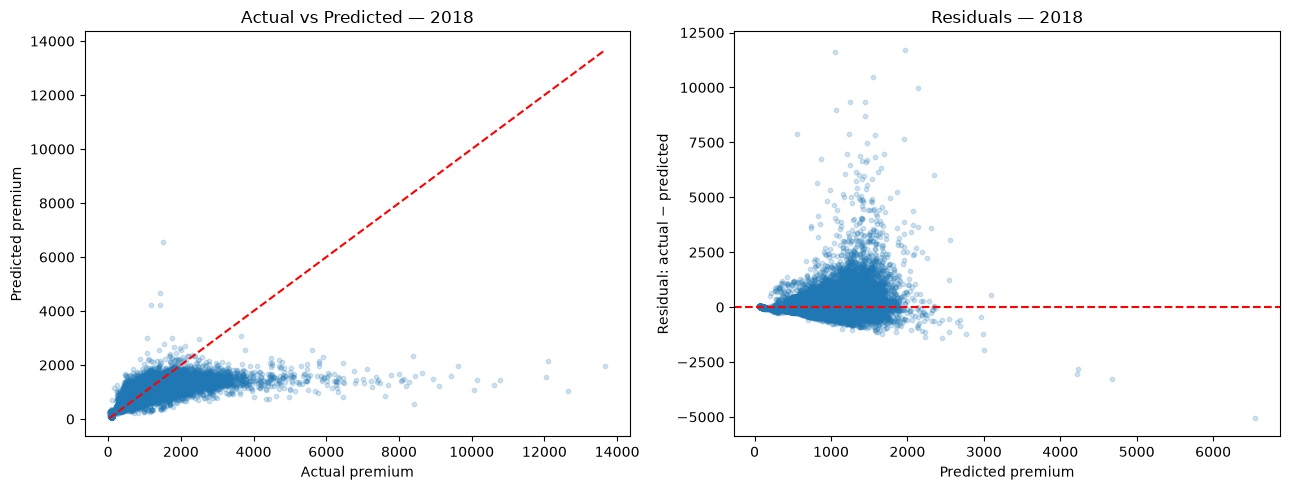

In [12]:
validation_results = pd.DataFrame({
    "actual_premium": y_val,
    "predicted_premium": val_predictions
})

# Positive residual means the model underpredicted.
validation_results["residual"] = (
    validation_results["actual_premium"]
    - validation_results["predicted_premium"]
)

validation_results["absolute_error"] = (
    validation_results["residual"].abs()
)

display(validation_results.head())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual versus predicted premiums.
axes[0].scatter(
    y_val, val_predictions,
    alpha=0.2, s=10
)

limits = [
    min(y_val.min(), val_predictions.min()),
    max(y_val.max(), val_predictions.max())
]

axes[0].plot(limits, limits, "r--")
axes[0].set_xlabel("Actual premium")
axes[0].set_ylabel("Predicted premium")
axes[0].set_title("Actual vs Predicted — 2018")

# Residuals versus predicted premiums.
axes[1].scatter(
    val_predictions,
    validation_results["residual"],
    alpha=0.2, s=10
)

axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted premium")
axes[1].set_ylabel("Residual: actual − predicted")
axes[1].set_title("Residuals — 2018")

plt.tight_layout()
plt.show()

In [13]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Train Ridge Regression.
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_processed, y_train_log)

# Predict on 2018 validation.
ridge_predictions_log = ridge_model.predict(X_val_processed)

# Convert predictions to original premium units.
ridge_predictions = np.exp(ridge_predictions_log)

# Evaluate.
mae = mean_absolute_error(y_val, ridge_predictions)
rmse = np.sqrt(mean_squared_error(y_val, ridge_predictions))
r2 = r2_score(y_val, ridge_predictions)

print("Ridge Regression — 2018 Validation")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")

Ridge Regression — 2018 Validation
MAE:  221.98
RMSE: 423.16
R²:   0.4385


In [14]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

alphas = [0.01, 0.1, 1, 10, 100, 1000]

results = []
best_mae = np.inf

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train_processed, y_train_log)

    # Convert log predictions to original premium units.
    train_predictions = np.exp(model.predict(X_train_processed))
    val_predictions = np.exp(model.predict(X_val_processed))

    train_mae = mean_absolute_error(y_train, train_predictions)
    val_mae = mean_absolute_error(y_val, val_predictions)

    results.append({
        "alpha": alpha,
        "train_MAE": train_mae,
        "val_MAE": val_mae,
        "train_RMSE": np.sqrt(
            mean_squared_error(y_train, train_predictions)
        ),
        "val_RMSE": np.sqrt(
            mean_squared_error(y_val, val_predictions)
        ),
        "train_R2": r2_score(y_train, train_predictions),
        "val_R2": r2_score(y_val, val_predictions)
    })

    if val_mae < best_mae:
        best_mae = val_mae
        best_ridge = model
        best_alpha = alpha

ridge_results = pd.DataFrame(results).sort_values("val_MAE")

display(ridge_results.round(4))

print("Best alpha:", best_alpha)

print("\nSelected Ridge — Training and Validation")
display(
    ridge_results.loc[
        ridge_results["alpha"].eq(best_alpha)
    ].round(4)
)

,alpha,train_MAE,val_MAE,train_RMSE,val_RMSE,train_R2,val_R2
0,0.01,208.3761,221.9588,413.7692,423.1157,0.4452,0.4387
1,0.10,208.3770,221.9604,413.7721,423.1195,0.4451,0.4386
2,1.00,208.3865,221.9765,413.8022,423.1573,0.4451,0.4385
3,10.00,208.5351,222.1547,414.1410,423.5627,0.4442,0.4375
4,100.00,211.0584,224.4686,418.2819,427.8685,0.4330,0.4260
5,1000.00,223.7979,235.5794,437.5224,445.8977,0.3796,0.3766


Best alpha: 0.01

Selected Ridge — Training and Validation


,alpha,train_MAE,val_MAE,train_RMSE,val_RMSE,train_R2,val_R2
0,0.01,208.3761,221.9588,413.7692,423.1157,0.4452,0.4387


In [15]:

from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import time

# Initialize RBF Kernel SVR (baseline)
svr_model = SVR(
    kernel="rbf",
    C=1.0,
    epsilon=0.1,
    gamma="scale",
    cache_size=1000
)

# Train on 2017 data using log-premium
start_time = time.time()

svr_model.fit(X_train_processed, y_train_log)

training_time = time.time() - start_time

# Predictions in original premium units
train_predictions = np.exp(
    svr_model.predict(X_train_processed)
)

val_predictions = np.exp(
    svr_model.predict(X_val_processed)
)

# Evaluate both training and validation
svr_results = pd.DataFrame({
    "Dataset": ["Training (2017)", "Validation (2018)"],
    "MAE": [
        mean_absolute_error(y_train, train_predictions),
        mean_absolute_error(y_val, val_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, train_predictions)),
        np.sqrt(mean_squared_error(y_val, val_predictions))
    ],
    "R2": [
        r2_score(y_train, train_predictions),
        r2_score(y_val, val_predictions)
    ]
})

print("RBF Kernel SVR — Baseline")
print(f"Training time: {training_time:.2f} seconds")
print(f"Support vectors: {len(svr_model.support_):,}")

display(svr_results.round(4))


RBF Kernel SVR — Baseline
Training time: 120.65 seconds
Support vectors: 30,528


,Dataset,MAE,RMSE,R2
0,Training (2017),147.4633,346.7423,0.6104
1,Validation (2018),171.7976,364.4806,0.5835


In [16]:

import optuna
import numpy as np
import pandas as pd
import time

from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone

optuna.logging.set_verbosity(optuna.logging.WARNING)

# ---------------------------------
# 1. Sample 20,000 training records
# ---------------------------------

rng = np.random.RandomState(42)

sample_idx = rng.choice(
    len(X_train),
    size=min(20000, len(X_train)),
    replace=False
)

X_sample = X_train.iloc[sample_idx]
y_sample = y_train.iloc[sample_idx]
y_sample_log = y_train_log.iloc[sample_idx]

groups_sample = train_df["ID_policy"].iloc[sample_idx]

# ---------------------------------
# 2. Two-fold group-aware CV
# ---------------------------------

cv = GroupKFold(n_splits=2)

# ---------------------------------
# 3. Bayesian objective
# ---------------------------------

def objective_fast(trial):

    C = trial.suggest_float(
        "C", 0.1, 100, log=True
    )

    gamma = trial.suggest_float(
        "gamma", 1e-4, 1.0, log=True
    )

    epsilon = trial.suggest_float(
        "epsilon", 0.01, 0.5, log=True
    )

    model = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("svr", SVR(
            kernel="rbf",
            C=C,
            gamma=gamma,
            epsilon=epsilon,
            cache_size=1000
        ))
    ])

    fold_maes = []

    for tr_idx, va_idx in cv.split(
        X_sample,
        y_sample_log,
        groups=groups_sample
    ):

        X_tr = X_sample.iloc[tr_idx]
        X_va = X_sample.iloc[va_idx]

        y_tr = y_sample_log.iloc[tr_idx]
        y_va = y_sample.iloc[va_idx]

        model.fit(X_tr, y_tr)

        predictions = np.exp(
            model.predict(X_va)
        )

        mae = mean_absolute_error(
            y_va,
            predictions
        )

        fold_maes.append(mae)

    return np.mean(fold_maes)


# ---------------------------------
# 4. Run 10 trials
# ---------------------------------

study_fast = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

start_time = time.time()

study_fast.optimize(
    objective_fast,
    n_trials=10,
    show_progress_bar=True
)

optimization_time = time.time() - start_time

print("\nBest hyperparameters:")
print(study_fast.best_params)

print("\nBest CV MAE:")
print(round(study_fast.best_value, 4))

print(
    "\nOptimization time (minutes):",
    round(optimization_time / 60, 2)
)


  0%|          | 0/10 [00:00<?, ?it/s]


Best hyperparameters:
{'C': 3.4890188454913864, 'gamma': 0.0234238498471129, 'epsilon': 0.011992724522955167}

Best CV MAE:
166.5846

Optimization time (minutes): 3.98


In [17]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

best_svr_fast = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("svr", SVR(
        kernel="rbf",
        **study_fast.best_params,
        cache_size=1000
    ))
])

start_time = time.time()

best_svr_fast.fit(X_train, y_train_log)

training_time = time.time() - start_time

train_pred = np.exp(best_svr_fast.predict(X_train))
val_pred = np.exp(best_svr_fast.predict(X_val))

def evaluate_svr(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(
            y_true, y_pred
        ) * 100
    }

svr_fast_results = pd.DataFrame(
    [
        evaluate_svr(y_train, train_pred),
        evaluate_svr(y_val, val_pred)
    ],
    index=["Training (2017)", "Validation (2018)"]
)

print("Optimized RBF SVR")
print("Best parameters:", study_fast.best_params)
print(f"Training time: {training_time:.2f} seconds")

display(svr_fast_results.round(4))


Optimized RBF SVR
Best parameters: {'C': 3.4890188454913864, 'gamma': 0.0234238498471129, 'epsilon': 0.011992724522955167}
Training time: 367.24 seconds


,MAE,RMSE,R2,MAPE (%)
Training (2017),140.9468,343.9744,0.6165,13.9008
Validation (2018),170.3918,364.7237,0.5829,16.1132


In [19]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

import numpy as np
import pandas as pd
import time

# ---------------------------------
# 1. Initialize Decision Tree
# ---------------------------------

dt_model = DecisionTreeRegressor(
    random_state=42
)

# ---------------------------------
# 2. Train on 2017
# ---------------------------------

start_time = time.time()

dt_model.fit(
    X_train_processed,
    y_train_log
)

training_time = time.time() - start_time

# ---------------------------------
# 3. Predict original premium
# ---------------------------------

dt_train_pred = np.exp(
    dt_model.predict(X_train_processed)
)

dt_val_pred = np.exp(
    dt_model.predict(X_val_processed)
)

# ---------------------------------
# 4. Evaluation
# ---------------------------------

def evaluate_dt(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(
            y_true, y_pred
        ) * 100
    }

dt_results = pd.DataFrame(
    [
        evaluate_dt(y_train, dt_train_pred),
        evaluate_dt(y_val, dt_val_pred)
    ],
    index=[
        "Training (2017)",
        "Validation (2018)"
    ]
)

print("Decision Tree Regressor — Baseline")
print(f"Training time: {training_time:.2f} seconds")
print("Tree depth:", dt_model.get_depth())
print("Leaf nodes:", dt_model.get_n_leaves())

display(dt_results.round(4))


Decision Tree Regressor — Baseline
Training time: 1.28 seconds
Tree depth: 43
Leaf nodes: 50430


,MAE,RMSE,R2,MAPE (%)
Training (2017),0.0498,2.0233,1.0000,0.0078
Validation (2018),208.7139,467.8487,0.3137,20.3915


In [20]:

model_comparison = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Baseline RBF SVR",
        "Optimized RBF SVR",
        "Decision Tree"
    ],
    "Validation MAE": [
        221.96,
        171.7976,
        170.3918,
        dt_results.loc["Validation (2018)", "MAE"]
    ],
    "Validation R2": [
        0.4387,
        0.5835,
        0.5829,
        dt_results.loc["Validation (2018)", "R2"]
    ]
})

display(
    model_comparison
    .sort_values("Validation MAE")
    .round(4)
)


,Model,Validation MAE,Validation R2
2,Optimized RBF SVR,170.3918,0.5829
1,Baseline RBF SVR,171.7976,0.5835
3,Decision Tree,208.7139,0.3137
0,Ridge Regression,221.9600,0.4387


In [22]:

import numpy as np
import pandas as pd
import time

from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import (
    RandomizedSearchCV,
    GroupKFold
)
from sklearn.compose import TransformedTargetRegressor
from scipy.stats import randint, uniform

# Decision tree with log target transformation
tree = TransformedTargetRegressor(
    regressor=DecisionTreeRegressor(random_state=42),
    func=np.log,
    inverse_func=np.exp,
    check_inverse=False
)

param_distributions = {
    "regressor__max_depth": randint(3, 25),
    "regressor__min_samples_split": randint(5, 100),
    "regressor__min_samples_leaf": randint(2, 60),
    "regressor__ccp_alpha": uniform(0.0, 0.001)
}

cv = GroupKFold(n_splits=3)

search = RandomizedSearchCV(
    estimator=tree,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1,
    refit=True
)

start_time = time.time()

search.fit(
    X_train_processed,
    y_train,
    groups=train_df["ID_policy"]
)

print("Best parameters:")
print(search.best_params_)

print("Best CV MAE:", -search.best_score_)

print("Search time:", round(time.time() - start_time, 2))


Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best parameters:
{'regressor__ccp_alpha': np.float64(5.522117123602399e-06), 'regressor__max_depth': 13, 'regressor__min_samples_leaf': 52, 'regressor__min_samples_split': 85}
Best CV MAE: 170.44797327847652
Search time: 4.31


In [23]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# Best fitted model
best_tree = search.best_estimator_

# Predictions in original premium units
dt_train_pred = best_tree.predict(X_train_processed)
dt_val_pred = best_tree.predict(X_val_processed)

def evaluate_tree(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(
            y_true, y_pred
        ) * 100
    }

tuned_tree_results = pd.DataFrame(
    [
        evaluate_tree(y_train, dt_train_pred),
        evaluate_tree(y_val, dt_val_pred)
    ],
    index=["Training (2017)", "Validation (2018)"]
)

display(tuned_tree_results.round(4))

fitted_tree = best_tree.regressor_

print("Tree depth:", fitted_tree.get_depth())
print("Leaf nodes:", fitted_tree.get_n_leaves())


,MAE,RMSE,R2,MAPE (%)
Training (2017),158.2029,347.4535,0.6088,15.9257
Validation (2018),179.9991,364.0693,0.5844,17.7515


Tree depth: 13
Leaf nodes: 449


In [24]:

import numpy as np
import pandas as pd
import time

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# Baseline Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

# Train on log-transformed premiums
rf_model.fit(X_train_processed, y_train_log)

training_time = time.time() - start_time

# Predict in original premium units
rf_train_pred = np.exp(
    rf_model.predict(X_train_processed)
)

rf_val_pred = np.exp(
    rf_model.predict(X_val_processed)
)

def evaluate_rf(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(
            y_true, y_pred
        ) * 100
    }

rf_results = pd.DataFrame(
    [
        evaluate_rf(y_train, rf_train_pred),
        evaluate_rf(y_val, rf_val_pred)
    ],
    index=["Training (2017)", "Validation (2018)"]
)

print("Random Forest — Baseline")
print(f"Training time: {training_time:.2f} seconds")
print("Number of trees:", rf_model.n_estimators)

display(rf_results.round(4))


Random Forest — Baseline
Training time: 7.23 seconds
Number of trees: 100


,MAE,RMSE,R2,MAPE (%)
Training (2017),56.1335,163.3979,0.9135,5.0014
Validation (2018),152.8914,325.2087,0.6684,14.6440


In [25]:

import numpy as np
import pandas as pd
import time

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.compose import TransformedTargetRegressor
from scipy.stats import randint, uniform

rf = TransformedTargetRegressor(
    regressor=RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    func=np.log,
    inverse_func=np.exp,
    check_inverse=False
)

param_distributions = {
    "regressor__n_estimators": randint(100, 301),
    "regressor__max_depth": randint(8, 31),
    "regressor__min_samples_split": randint(2, 31),
    "regressor__min_samples_leaf": randint(1, 21),
    "regressor__max_features": uniform(0.5, 0.5)
}

rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=GroupKFold(n_splits=3),
    n_jobs=-1,
    random_state=42,
    verbose=1,
    refit=True
)

start_time = time.time()

rf_search.fit(
    X_train_processed,
    y_train,
    groups=train_df["ID_policy"]
)

print("Best parameters:")
print(rf_search.best_params_)

print("Best CV MAE:", -rf_search.best_score_)
print("Search time:", round(time.time() - start_time, 2))


Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best parameters:
{'regressor__max_depth': 22, 'regressor__max_features': np.float64(0.5826334695315012), 'regressor__min_samples_leaf': 7, 'regressor__min_samples_split': 10, 'regressor__n_estimators': 187}
Best CV MAE: 153.4533635973557
Search time: 306.89


In [26]:


import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# Best fitted Random Forest
best_rf = rf_search.best_estimator_

# Predictions in original premium units
rf_train_pred_tuned = best_rf.predict(X_train_processed)
rf_val_pred_tuned = best_rf.predict(X_val_processed)

def evaluate_rf(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(
            y_true, y_pred
        ) * 100
    }

rf_tuned_results = pd.DataFrame(
    [
        evaluate_rf(y_train, rf_train_pred_tuned),
        evaluate_rf(y_val, rf_val_pred_tuned)
    ],
    index=["Training (2017)", "Validation (2018)"]
)

print("Optimized Random Forest — Results")
display(rf_tuned_results.round(4))

print("\nBest parameters:")
print(rf_search.best_params_)


Optimized Random Forest — Results


,MAE,RMSE,R2,MAPE (%)
Training (2017),113.5059,291.4669,0.7247,10.7581
Validation (2018),158.4954,338.0317,0.6417,15.2778



Best parameters:
{'regressor__max_depth': 22, 'regressor__max_features': np.float64(0.5826334695315012), 'regressor__min_samples_leaf': 7, 'regressor__min_samples_split': 10, 'regressor__n_estimators': 187}


In [27]:
display(rf_tuned_results.round(4))

,MAE,RMSE,R2,MAPE (%)
Training (2017),113.5059,291.4669,0.7247,10.7581
Validation (2018),158.4954,338.0317,0.6417,15.2778


In [28]:

import numpy as np
import pandas as pd
import time

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# Baseline Extra Trees
et_model = ExtraTreesRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

et_model.fit(X_train_processed, y_train_log)

training_time = time.time() - start_time

# Predictions in original premium units
et_train_pred = np.exp(
    et_model.predict(X_train_processed)
)

et_val_pred = np.exp(
    et_model.predict(X_val_processed)
)

def evaluate_et(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(
            y_true, y_pred
        ) * 100
    }

et_results = pd.DataFrame(
    [
        evaluate_et(y_train, et_train_pred),
        evaluate_et(y_val, et_val_pred)
    ],
    index=["Training (2017)", "Validation (2018)"]
)

print("Extra Trees — Baseline")
print(f"Training time: {training_time:.2f} seconds")
print("Number of trees:", et_model.n_estimators)

display(et_results.round(4))


Extra Trees — Baseline
Training time: 5.95 seconds
Number of trees: 100


,MAE,RMSE,R2,MAPE (%)
Training (2017),0.0498,2.0233,1.000,0.0078
Validation (2018),138.5660,297.2461,0.723,13.3369


In [29]:

import numpy as np
import time

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.compose import TransformedTargetRegressor
from scipy.stats import randint, uniform

# Extra Trees with log-transformed target
et = TransformedTargetRegressor(
    regressor=ExtraTreesRegressor(
        random_state=42,
        n_jobs=1
    ),
    func=np.log,
    inverse_func=np.exp,
    check_inverse=False
)

param_distributions = {
    "regressor__n_estimators": randint(100, 301),
    "regressor__max_depth": [None, 15, 20, 25, 30, 40],
    "regressor__min_samples_split": randint(2, 21),
    "regressor__min_samples_leaf": randint(1, 11),
    "regressor__max_features": uniform(0.5, 0.5)
}

et_search = RandomizedSearchCV(
    estimator=et,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=GroupKFold(n_splits=3),
    n_jobs=-1,
    random_state=42,
    verbose=1,
    refit=True
)

start_time = time.time()

et_search.fit(
    X_train_processed,
    y_train,
    groups=train_df["ID_policy"]
)

print("Best parameters:")
print(et_search.best_params_)

print("Best CV MAE:", -et_search.best_score_)
print("Search time:", round(time.time() - start_time, 2))


Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best parameters:
{'regressor__max_depth': 40, 'regressor__max_features': np.float64(0.5156566462277793), 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 13, 'regressor__n_estimators': 261}
Best CV MAE: 152.48319315274384
Search time: 327.05


In [30]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)
import pandas as pd
import numpy as np

best_et = et_search.best_estimator_

et_train_pred_tuned = best_et.predict(X_train_processed)
et_val_pred_tuned = best_et.predict(X_val_processed)

def evaluate_et(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(
            y_true, y_pred
        ) * 100
    }

et_tuned_results = pd.DataFrame(
    [
        evaluate_et(y_train, et_train_pred_tuned),
        evaluate_et(y_val, et_val_pred_tuned)
    ],
    index=["Training (2017)", "Validation (2018)"]
)

display(et_tuned_results.round(4))


,MAE,RMSE,R2,MAPE (%)
Training (2017),96.3040,266.4740,0.7699,8.8306
Validation (2018),148.6945,325.9672,0.6668,14.1499


In [31]:

import numpy as np
import pandas as pd
import time

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# Baseline gradient boosting
hgb_model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    random_state=42
)

start_time = time.time()

# Train on log-transformed premiums
hgb_model.fit(X_train_processed, y_train_log)

training_time = time.time() - start_time

# Predictions in original premium units
hgb_train_pred = np.exp(
    hgb_model.predict(X_train_processed)
)

hgb_val_pred = np.exp(
    hgb_model.predict(X_val_processed)
)

def evaluate_hgb(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(
            y_true, y_pred
        ) * 100
    }

hgb_results = pd.DataFrame(
    [
        evaluate_hgb(y_train, hgb_train_pred),
        evaluate_hgb(y_val, hgb_val_pred)
    ],
    index=["Training (2017)", "Validation (2018)"]
)

print("HistGradientBoosting — Baseline")
print(f"Training time: {training_time:.2f} seconds")

display(hgb_results.round(4))


HistGradientBoosting — Baseline
Training time: 0.82 seconds


,MAE,RMSE,R2,MAPE (%)
Training (2017),145.5199,332.3949,0.6419,14.3735
Validation (2018),166.7947,346.6744,0.6232,16.1837


In [33]:

import numpy as np
import pandas as pd
import time

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from scipy.stats import randint, loguniform

hgb_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", TransformedTargetRegressor(
        regressor=HistGradientBoostingRegressor(
            random_state=42,
            early_stopping=False
        ),
        func=np.log,
        inverse_func=np.exp,
        check_inverse=False
    ))
])

param_distributions = {
    "model__regressor__max_iter": randint(100, 501),
    "model__regressor__learning_rate": loguniform(0.02, 0.2),
    "model__regressor__max_leaf_nodes": randint(15, 64),
    "model__regressor__min_samples_leaf": randint(10, 101),
    "model__regressor__l2_regularization": loguniform(1e-4, 10.0)
}

hgb_search = RandomizedSearchCV(
    estimator=hgb_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=GroupKFold(n_splits=3),
    n_jobs=-1,
    random_state=42,
    verbose=1,
    refit=True
)

start_time = time.time()

hgb_search.fit(
    X_train,
    y_train,
    groups=train_df["ID_policy"]
)

print("Best parameters:")
print(hgb_search.best_params_)

print("Best CV MAE:", -hgb_search.best_score_)
print("Search time:", round(time.time() - start_time, 2))


Fitting 3 folds for each of 20 candidates, totalling 60 fits


OSError: [WinError 1450] Insufficient system resources exist to complete the requested service

In [35]:

# Identify numerical predictors
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical predictors
categorical_features = X_train.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

# Verify feature counts
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(numeric_features) + len(categorical_features))

print("\nNumerical columns:")
print(numeric_features)

print("\nCategorical columns:")
print(categorical_features)

# Ensure every predictor is accounted for
assert len(numeric_features) + len(categorical_features) == X_train.shape[1], \
    "Some predictor columns have unsupported data types."


Numerical features: 19
Categorical features: 8
Total features: 27

Numerical columns:
['age', 'seniority_insured', 'seniority_policy', 'exposure_time', 'n_insured_pc', 'n_insured_mun', 'n_insured_prov', 'cost_claims_year', 'n_medical_services', 'IICIMUN', 'IICIPROV', 'C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T', 'C_GE_P', 'C_GE_S', 'C_GE_T']

Categorical columns:
['gender', 'type_policy', 'type_policy_dg', 'type_product', 'reimbursement', 'distribution_channel', 'C_H', 'C_C']


In [36]:

import numpy as np
import pandas as pd
import time

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.compose import (
    ColumnTransformer,
    TransformedTargetRegressor
)
from sklearn.preprocessing import (
    OneHotEncoder,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    RandomizedSearchCV,
    GroupKFold
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)
from scipy.stats import randint, loguniform

# ==========================================
# 1. Verify data
# ==========================================

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(train_df) == len(X_train)
assert (np.asarray(y_train) > 0).all()
assert (np.asarray(y_val) > 0).all()

groups = train_df["ID_policy"].to_numpy()

# ==========================================
# 2. Preprocessing for HistGradientBoosting
# ==========================================

# Numeric features:
# Keep missing values as NaN.
# HistGradientBoosting handles them natively.

# Categorical features:
# Impute missing categories and one-hot encode.

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

hgb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop",
    sparse_threshold=0
)

# ==========================================
# 3. HistGradientBoosting model
# ==========================================

hgb_regressor = HistGradientBoostingRegressor(
    random_state=42,
    early_stopping=False
)

# Train on log(target), predict in original units
hgb_target_model = TransformedTargetRegressor(
    regressor=hgb_regressor,
    func=np.log,
    inverse_func=np.exp,
    check_inverse=False
)

# ==========================================
# 4. Full pipeline
# ==========================================

hgb_pipeline = Pipeline([
    ("preprocessing", hgb_preprocessor),
    ("model", hgb_target_model)
])

# ==========================================
# 5. Hyperparameter search space
# ==========================================

param_distributions = {
    "model__regressor__max_iter": randint(100, 501),

    "model__regressor__learning_rate": loguniform(
        0.02, 0.2
    ),

    "model__regressor__max_leaf_nodes": randint(
        15, 64
    ),

    "model__regressor__min_samples_leaf": randint(
        10, 101
    ),

    "model__regressor__l2_regularization": loguniform(
        1e-4, 10.0
    )
}

# ==========================================
# 6. Group-aware cross-validation
# ==========================================

cv = GroupKFold(n_splits=3)

# ==========================================
# 7. RandomizedSearchCV
# ==========================================

hgb_search = RandomizedSearchCV(
    estimator=hgb_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=1,
    pre_dispatch=1,
    random_state=42,
    verbose=1,
    refit=True,
    error_score="raise"
)

# ==========================================
# 8. Train and optimize
# ==========================================

start_time = time.time()

hgb_search.fit(
    X_train,
    y_train,
    groups=groups
)

search_time = time.time() - start_time

print("\nHistGradientBoosting Optimization Completed")

print("\nBest Hyperparameters:")
for param, value in hgb_search.best_params_.items():
    print(f"{param}: {value}")

print(
    f"\nBest CV MAE: {-hgb_search.best_score_:.4f}"
)

print(
    f"Total Search Time: {search_time:.2f} seconds"
)

# ==========================================
# 9. Best fitted model
# ==========================================

best_hgb = hgb_search.best_estimator_

# ==========================================
# 10. Training and validation predictions
# ==========================================

hgb_train_pred_tuned = best_hgb.predict(X_train)
hgb_val_pred_tuned = best_hgb.predict(X_val)

# ==========================================
# 11. Evaluation function
# ==========================================

def evaluate_hgb(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(
            y_true, y_pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(
            y_true, y_pred
        ),
        "MAPE (%)": mean_absolute_percentage_error(
            y_true, y_pred
        ) * 100
    }

# ==========================================
# 12. Results
# ==========================================

hgb_tuned_results = pd.DataFrame(
    [
        evaluate_hgb(
            y_train, hgb_train_pred_tuned
        ),
        evaluate_hgb(
            y_val, hgb_val_pred_tuned
        )
    ],
    index=[
        "Training (2017)",
        "Validation (2018)"
    ]
)

print("\nOptimized HistGradientBoosting Results")
display(hgb_tuned_results.round(4))

# ==========================================
# 13. Compare with baseline
# ==========================================

comparison = pd.DataFrame({
    "Model": [
        "Baseline HistGradientBoosting",
        "Tuned HistGradientBoosting",
        "Baseline Extra Trees"
    ],
    "Validation MAE": [
        166.7947,
        hgb_tuned_results.loc[
            "Validation (2018)", "MAE"
        ],
        138.5660
    ],
    "Validation R2": [
        0.6232,
        hgb_tuned_results.loc[
            "Validation (2018)", "R2"
        ],
        0.7230
    ]
})

print("\nModel Comparison")
display(
    comparison.sort_values(
        "Validation MAE"
    ).round(4)
)


Fitting 3 folds for each of 15 candidates, totalling 45 fits

HistGradientBoosting Optimization Completed

Best Hyperparameters:
model__regressor__l2_regularization: 0.017732528513177907
model__regressor__learning_rate: 0.04967984494099453
model__regressor__max_iter: 369
model__regressor__max_leaf_nodes: 45
model__regressor__min_samples_leaf: 57

Best CV MAE: 148.4037
Total Search Time: 79.78 seconds

Optimized HistGradientBoosting Results


,MAE,RMSE,R2,MAPE (%)
Training (2017),132.3675,318.8127,0.6706,12.7685
Validation (2018),161.8688,340.3971,0.6367,15.6850



Model Comparison


,Model,Validation MAE,Validation R2
2,Baseline Extra Trees,138.5660,0.7230
1,Tuned HistGradientBoosting,161.8688,0.6367
0,Baseline HistGradientBoosting,166.7947,0.6232


In [38]:
%pip install xgboost
import numpy as np
import pandas as pd
import time

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# =====================================
# 1. Initialize XGBoost
# =====================================

xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="reg:squarederror",
    tree_method="hist",
    device="cpu",
    random_state=42,
    n_jobs=4
)

# =====================================
# 2. Train on 2017
# =====================================

start_time = time.time()

xgb_model.fit(
    X_train_processed,
    y_train_log
)

training_time = time.time() - start_time

# =====================================
# 3. Predict in original premium units
# =====================================

xgb_train_pred = np.exp(
    xgb_model.predict(X_train_processed)
)

xgb_val_pred = np.exp(
    xgb_model.predict(X_val_processed)
)

# =====================================
# 4. Evaluation
# =====================================

def evaluate_xgb(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(
            y_true, y_pred
        ) * 100
    }

xgb_results = pd.DataFrame(
    [
        evaluate_xgb(y_train, xgb_train_pred),
        evaluate_xgb(y_val, xgb_val_pred)
    ],
    index=[
        "Training (2017)",
        "Validation (2018)"
    ]
)

print("XGBoost — Baseline")
print(f"Training time: {training_time:.2f} seconds")

display(xgb_results.round(4))


   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   - -------------------------------------- 2.1/48.9 MB 13.3 MB/s eta 0:00:04
   --- ------------------------------------ 4.7/48.9 MB 12.3 MB/s eta 0:00:04
   ----- ---------------------------------- 7.1/48.9 MB 11.9 MB/s eta 0:00:04
   ------- -------------------------------- 9.7/48.9 MB 12.3 MB/s eta 0:00:04
   --------- ------------------------------ 12.1/48.9 MB 12.2 MB/s eta 0:00:04
   ----------- ---------------------------- 14.7/48.9 MB 12.2 MB/s eta 0:00:03
   ------------- -------------------------- 17.0/48.9 MB 12.1 MB/s eta 0:00:03
   ---------------- ----------------------- 19.7/48.9 MB 12.1 MB/s eta 0:00:03
   ----------------- ---------------------- 21.8/48.9 MB 12.1 MB/s eta 0:00:03
   ------------------- -------------------- 24.4/48.9 MB 12.0 MB/s eta 0:00:03
   --------------------- ------------------ 26.7/48.9 MB 12.0 MB/s eta 0:00:02
   ----------------------- ---------------- 28.8/48.9 MB 11.8 MB/


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


XGBoost — Baseline
Training time: 1.24 seconds


,MAE,RMSE,R2,MAPE (%)
Training (2017),143.9737,326.5453,0.6544,14.1706
Validation (2018),170.2991,352.2284,0.6110,16.3299


In [39]:

comparison = pd.DataFrame({
    "Model": [
        "Extra Trees",
        "Random Forest",
        "HistGradientBoosting",
        "XGBoost"
    ],
    "Validation MAE": [
        138.5660,
        152.8914,
        161.8688,
        xgb_results.loc["Validation (2018)", "MAE"]
    ],
    "Validation R2": [
        0.7230,
        0.6684,
        0.6367,
        xgb_results.loc["Validation (2018)", "R2"]
    ]
})

display(
    comparison.sort_values(
        "Validation MAE"
    ).round(4)
)


,Model,Validation MAE,Validation R2
0,Extra Trees,138.5660,0.7230
1,Random Forest,152.8914,0.6684
2,HistGradientBoosting,161.8688,0.6367
3,XGBoost,170.2991,0.6110


In [40]:

# XGBoost — Training and Validation Results

display(xgb_results.round(4))

# Check generalization gap
train_mae = xgb_results.loc["Training (2017)", "MAE"]
val_mae = xgb_results.loc["Validation (2018)", "MAE"]

print(f"Training MAE: {train_mae:.4f}")
print(f"Validation MAE: {val_mae:.4f}")
print(f"MAE Gap: {val_mae - train_mae:.4f}")


,MAE,RMSE,R2,MAPE (%)
Training (2017),143.9737,326.5453,0.6544,14.1706
Validation (2018),170.2991,352.2284,0.6110,16.3299


Training MAE: 143.9737
Validation MAE: 170.2991
MAE Gap: 26.3253


In [41]:

import numpy as np
import pandas as pd
import time

from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)
from scipy.stats import randint, uniform, loguniform

# =========================================
# 1. Base estimator
# =========================================

xgb_base = XGBRegressor(
    objective="reg:squarederror",
    tree_method="hist",
    device="cpu",
    random_state=42,
    n_jobs=4
)

# =========================================
# 2. Hyperparameter search space
# =========================================

param_distributions = {
    "n_estimators": randint(150, 601),
    "max_depth": randint(3, 13),
    "learning_rate": loguniform(0.02, 0.2),
    "min_child_weight": randint(1, 16),
    "subsample": uniform(0.7, 0.3),
    "colsample_bytree": uniform(0.6, 0.4),
    "reg_lambda": loguniform(0.1, 20.0),
    "reg_alpha": loguniform(1e-4, 2.0)
}

# =========================================
# 3. Group-aware cross-validation
# =========================================

cv = GroupKFold(n_splits=3)

# =========================================
# 4. RandomizedSearchCV
# =========================================

xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=1,
    pre_dispatch=1,
    random_state=42,
    verbose=1,
    refit=True,
    error_score="raise"
)

# =========================================
# 5. Train using 2017 data
# =========================================

start_time = time.time()

xgb_search.fit(
    X_train_processed,
    y_train_log,
    groups=train_df["ID_policy"]
)

search_time = time.time() - start_time

print("Best Parameters:")
print(xgb_search.best_params_)

print(
    f"\nBest CV MAE (log scale): "
    f"{-xgb_search.best_score_:.6f}"
)

print(
    f"Search Time: {search_time:.2f} seconds"
)

# =========================================
# 6. Best model
# =========================================

best_xgb = xgb_search.best_estimator_

# =========================================
# 7. Predictions in original premium units
# =========================================

xgb_train_pred_tuned = np.exp(
    best_xgb.predict(X_train_processed)
)

xgb_val_pred_tuned = np.exp(
    best_xgb.predict(X_val_processed)
)

# =========================================
# 8. Evaluation
# =========================================

def evaluate_xgb(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(
            y_true, y_pred
        ) * 100
    }

xgb_tuned_results = pd.DataFrame(
    [
        evaluate_xgb(y_train, xgb_train_pred_tuned),
        evaluate_xgb(y_val, xgb_val_pred_tuned)
    ],
    index=[
        "Training (2017)",
        "Validation (2018)"
    ]
)

print("\nTuned XGBoost Results:")
display(xgb_tuned_results.round(4))



Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters:
{'colsample_bytree': np.float64(0.9464704583099741), 'learning_rate': np.float64(0.0798261175712336), 'max_depth': 10, 'min_child_weight': 3, 'n_estimators': 299, 'reg_alpha': np.float64(0.00017483480500499304), 'reg_lambda': np.float64(4.585015749617613), 'subsample': np.float64(0.981565812704725)}

Best CV MAE (log scale): 0.142746
Search Time: 183.10 seconds

Tuned XGBoost Results:


,MAE,RMSE,R2,MAPE (%)
Training (2017),79.2284,198.5095,0.8723,7.5568
Validation (2018),157.5190,332.5668,0.6532,15.0228


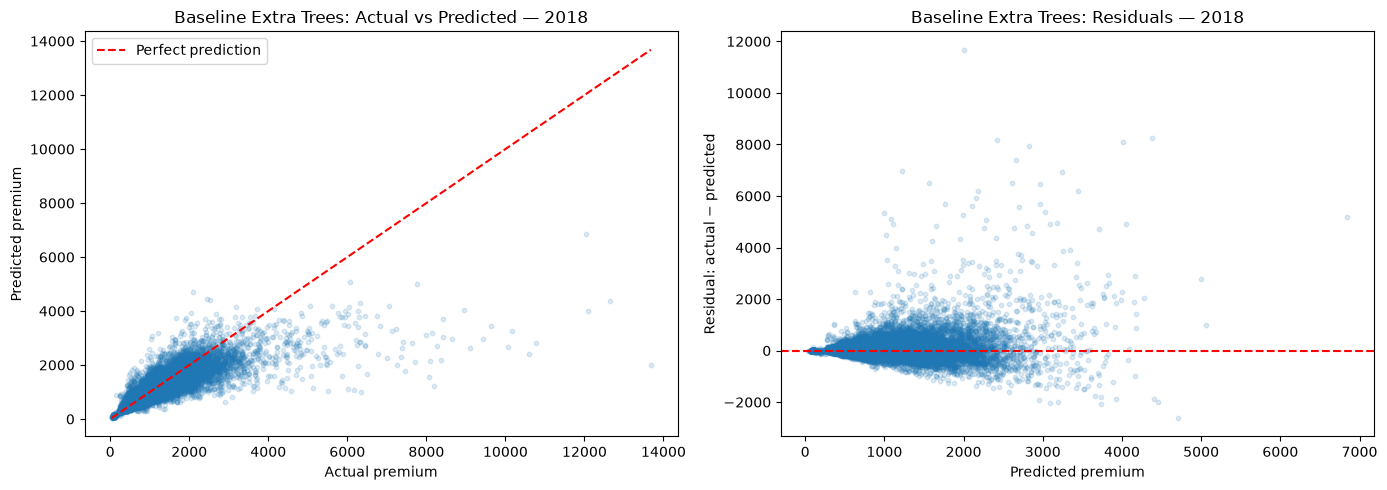

Mean residual: 45.92
Median absolute error: 82.05
90th percentile absolute error: 276.51


,actual_premium,predicted_premium,residual,absolute_error
58721,13679.44,2004.74,11674.70,11674.70
74717,12647.22,4383.72,8263.50,8263.50
56636,10600.86,2426.73,8174.13,8174.13
56233,12101.82,4016.01,8085.81,8085.81
60785,10765.59,2824.17,7941.42,7941.42
65494,10055.16,2659.67,7395.49,7395.49
56734,8181.42,1222.80,6958.62,6958.62
60063,10155.55,3243.43,6912.12,6912.12
78402,8063.84,1558.41,6505.43,6505.43
58586,9107.58,2617.35,6490.23,6490.23


In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Baseline Extra Trees validation predictions are already
# in original premium units—do not exponentiate them again.
actual = np.asarray(y_val).ravel()
predicted = np.asarray(et_val_pred).ravel()

assert len(actual) == len(predicted)
assert np.isfinite(actual).all()
assert np.isfinite(predicted).all()

et_validation_errors = pd.DataFrame({
    "actual_premium": actual,
    "predicted_premium": predicted
}, index=y_val.index)

# Positive residual = underprediction.
et_validation_errors["residual"] = actual - predicted
et_validation_errors["absolute_error"] = np.abs(actual - predicted)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Actual versus predicted
axes[0].scatter(actual, predicted, alpha=0.15, s=10)

lower = min(actual.min(), predicted.min())
upper = max(actual.max(), predicted.max())

axes[0].plot(
    [lower, upper], [lower, upper],
    "r--", label="Perfect prediction"
)
axes[0].set_xlabel("Actual premium")
axes[0].set_ylabel("Predicted premium")
axes[0].set_title("Baseline Extra Trees: Actual vs Predicted — 2018")
axes[0].legend()

# 2. Residuals versus predicted
axes[1].scatter(
    predicted,
    et_validation_errors["residual"],
    alpha=0.15,
    s=10
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted premium")
axes[1].set_ylabel("Residual: actual − predicted")
axes[1].set_title("Baseline Extra Trees: Residuals — 2018")

plt.tight_layout()
plt.show()

print(
    "Mean residual:",
    round(et_validation_errors["residual"].mean(), 2)
)
print(
    "Median absolute error:",
    round(et_validation_errors["absolute_error"].median(), 2)
)
print(
    "90th percentile absolute error:",
    round(et_validation_errors["absolute_error"].quantile(0.90), 2)
)

display(
    et_validation_errors
    .nlargest(10, "absolute_error")
    .round(2)
)

In [43]:
# Define premium bands using TRAINING premiums only.
q50, q90, q99 = y_train.quantile([0.50, 0.90, 0.99])

band_labels = [
    "Up to training P50",
    "Training P50–P90",
    "Training P90–P99",
    "Above training P99"
]

et_validation_errors["premium_band"] = pd.cut(
    et_validation_errors["actual_premium"],
    bins=[-np.inf, q50, q90, q99, np.inf],
    labels=band_labels
)

band_summary = (
    et_validation_errors
    .groupby("premium_band", observed=True)
    .agg(
        Count=("actual_premium", "size"),
        Mean_Actual=("actual_premium", "mean"),
        Mean_Predicted=("predicted_premium", "mean"),
        MAE=("absolute_error", "mean"),
        Mean_Residual=("residual", "mean"),
        RMSE=("residual", lambda x: np.sqrt(np.mean(x**2))),
        Underprediction_Pct=("residual", lambda x: (x > 0).mean() * 100)
    )
)

print(f"Training thresholds: P50={q50:.2f}, P90={q90:.2f}, P99={q99:.2f}")
display(band_summary.round(2))

Training thresholds: P50=836.28, P90=1426.12, P99=2888.36


,Count,Mean_Actual,Mean_Predicted,MAE,Mean_Residual,RMSE,Underprediction_Pct
premium_band,,,,,,,
Up to training P50,25820,576.88,607.39,71.01,-30.51,108.48,38.24
Training P50–P90,21701,1047.69,987.90,135.11,59.80,177.47,73.15
Training P90–P99,5451,1838.66,1650.97,314.96,187.69,430.94,73.05
Above training P99,549,4131.33,2447.27,1701.13,1684.06,2229.63,96.72


In [44]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# 1. Copy baseline Extra Trees settings.
# clone() creates an unfitted model.
et_raw_model = clone(et_model)

# 2. Train on ORIGINAL premiums.
et_raw_model.fit(X_train_processed, y_train)

# Predictions are already in original premium units.
et_raw_train_pred = et_raw_model.predict(X_train_processed)
et_raw_val_pred = et_raw_model.predict(X_val_processed)


# 3. Training and validation metrics.
def evaluate_premium(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": (
            mean_absolute_percentage_error(y_true, y_pred) * 100
        )
    }


et_raw_results = pd.DataFrame(
    [
        evaluate_premium(y_train, et_raw_train_pred),
        evaluate_premium(y_val, et_raw_val_pred)
    ],
    index=["Training (2017)", "Validation (2018)"]
)

print("Extra Trees — Original-Premium Training")
display(et_raw_results.round(4))


# 4. Compare both models on the SAME validation observations.
# et_model is your existing baseline trained on log-premium.
et_log_val_pred = np.exp(
    et_model.predict(X_val_processed)
)

target_comparison = pd.DataFrame(
    [
        evaluate_premium(y_val, et_log_val_pred),
        evaluate_premium(y_val, et_raw_val_pred)
    ],
    index=["Log-target Extra Trees", "Raw-target Extra Trees"]
)

print("\nValidation Comparison — 2018")
display(target_comparison.round(4))


# 5. Define identical bands using training premiums only.
q50, q90, q99 = y_train.quantile([0.50, 0.90, 0.99])

band_edges = [-np.inf, q50, q90, q99, np.inf]

band_labels = [
    "Up to training P50",
    "Training P50–P90",
    "Training P90–P99",
    "Above training P99"
]


def summarize_premium_bands(y_true, y_pred):
    errors = pd.DataFrame({
        "actual_premium": np.asarray(y_true).ravel(),
        "predicted_premium": np.asarray(y_pred).ravel()
    })

    errors["residual"] = (
        errors["actual_premium"] - errors["predicted_premium"]
    )
    errors["absolute_error"] = errors["residual"].abs()

    errors["premium_band"] = pd.cut(
        errors["actual_premium"],
        bins=band_edges,
        labels=band_labels
    )

    return (
        errors.groupby("premium_band", observed=True)
        .agg(
            Count=("actual_premium", "size"),
            Mean_Actual=("actual_premium", "mean"),
            Mean_Predicted=("predicted_premium", "mean"),
            MAE=("absolute_error", "mean"),
            Mean_Residual=("residual", "mean"),
            RMSE=(
                "residual",
                lambda x: np.sqrt(np.mean(x**2))
            ),
            Underprediction_Pct=(
                "residual",
                lambda x: (x > 0).mean() * 100
            )
        )
    )


log_band_summary = summarize_premium_bands(
    y_val, et_log_val_pred
)

raw_band_summary = summarize_premium_bands(
    y_val, et_raw_val_pred
)

band_comparison = pd.concat(
    {
        "Log target": log_band_summary,
        "Raw target": raw_band_summary
    },
    names=["Training target"]
).swaplevel(0, 1).sort_index(level=0, sort_remaining=False)

print("\nValidation Errors by Premium Band")
display(band_comparison.round(2))

Extra Trees — Original-Premium Training


,MAE,RMSE,R2,MAPE (%)
Training (2017),0.0502,2.0158,1.000,0.008
Validation (2018),144.8891,292.3648,0.732,14.508



Validation Comparison — 2018


,MAE,RMSE,R2,MAPE (%)
Log-target Extra Trees,138.5660,297.2461,0.723,13.3369
Raw-target Extra Trees,144.8891,292.3648,0.732,14.5080



Validation Errors by Premium Band


Count  Mean_Actual  Mean_Predicted  \
premium_band       Training target                                       
Up to training P50 Log target       25820       576.88          607.39   
                   Raw target       25820       576.88          622.46   
Training P50–P90   Log target       21701      1047.69          987.90   
                   Raw target       21701      1047.69         1021.70   
Training P90–P99   Log target        5451      1838.66         1650.97   
                   Raw target        5451      1838.66         1762.24   
Above training P99 Log target         549      4131.33         2447.27   
                   Raw target         549      4131.33         2726.79   

                                        MAE  Mean_Residual     RMSE  \
premium_band       Training target                                    
Up to training P50 Log target         71.01         -30.51   108.48   
                   Raw target         80.49         -45.59   128.80   
Training P50–P90   Log target        135.11          59.80   177.47   
                   Raw target        144.52          25.99   206.90   
Training P90–P99   Log target        314.96         187.69   430.94   
                   Raw target        318.74          76.42   455.27   
Above training P99 Log target       1701.13        1684.06  2229.63   
                   Raw target       1461.90        1404.54  1950.03   

                                    Underprediction_Pct  
premium_band       Training target                       
Up to training P50 Log target                     38.24  
                   Raw target                     34.04  
Training P50–P90   Log target                     73.15  
                   Raw target                     68.72  
Training P90–P99   Log target                     73.05  
                   Raw target                     62.36  
Above training P99 Log target                     96.72  
                   Raw target                     93.44

In [45]:
import numpy as np
import pandas as pd

# Match policy information to validation targets by index.
group_errors = val_df.loc[
    y_val.index,
    ["type_product", "type_policy_dg"]
].copy()

group_errors["actual"] = y_val
group_errors["predicted"] = np.exp(
    et_model.predict(X_val_processed)
)

group_errors["residual"] = (
    group_errors["actual"] - group_errors["predicted"]
)
group_errors["absolute_error"] = group_errors["residual"].abs()
group_errors["squared_error"] = group_errors["residual"] ** 2
group_errors["percentage_error"] = (
    group_errors["absolute_error"] / group_errors["actual"] * 100
)


def summarize_group_errors(column):
    summary = (
        group_errors.groupby(column, dropna=False)
        .agg(
            Count=("actual", "size"),
            Mean_Actual=("actual", "mean"),
            Mean_Predicted=("predicted", "mean"),
            MAE=("absolute_error", "mean"),
            MSE=("squared_error", "mean"),
            MAPE_Pct=("percentage_error", "mean"),
            Mean_Residual=("residual", "mean"),
            Total_Absolute_Error=("absolute_error", "sum")
        )
    )

    summary["RMSE"] = np.sqrt(summary.pop("MSE"))

    summary["Absolute_Error_Share_Pct"] = (
        summary.pop("Total_Absolute_Error")
        / group_errors["absolute_error"].sum()
        * 100
    )

    return summary[
        [
            "Count", "Mean_Actual", "Mean_Predicted",
            "MAE", "RMSE", "MAPE_Pct", "Mean_Residual",
            "Absolute_Error_Share_Pct"
        ]
    ].sort_values("MAE", ascending=False)


product_error_summary = summarize_group_errors("type_product")
policy_error_summary = summarize_group_errors("type_policy_dg")

print("Extra Trees — Validation Errors by Product")
display(product_error_summary.round(2))

print("\nExtra Trees — Validation Errors by Detailed Policy Type")
display(policy_error_summary.round(2))

Extra Trees — Validation Errors by Product


,Count,Mean_Actual,Mean_Predicted,MAE,RMSE,MAPE_Pct,Mean_Residual,Absolute_Error_Share_Pct
type_product,,,,,,,,
P,8175,995.29,958.53,159.72,384.41,14.42,36.76,17.61
I,684,1178.11,1107.74,148.86,365.00,13.18,70.37,1.37
S,42349,962.36,912.20,141.47,284.58,13.43,50.16,80.78
D,2313,96.99,103.62,7.64,8.33,7.85,-6.63,0.24



Extra Trees — Validation Errors by Detailed Policy Type


,Count,Mean_Actual,Mean_Predicted,MAE,RMSE,MAPE_Pct,Mean_Residual,Absolute_Error_Share_Pct
type_policy_dg,,,,,,,,
C4,4,535.53,847.22,311.69,326.65,59.78,-311.69,0.02
I,25095,1074.55,1032.74,178.74,402.41,14.55,41.81,60.48
C3,15013,884.93,821.34,113.25,139.48,12.51,63.59,22.93
C1,5041,667.98,626.74,93.06,188.95,12.74,41.24,6.33
S,7165,737.77,710.87,92.49,154.64,11.99,26.90,8.94
C2,1203,843.47,798.51,80.93,132.88,8.68,44.96,1.31


In [46]:
# Use the same training-defined premium bands.
q50, q90, q99 = y_train.quantile([0.50, 0.90, 0.99])

group_errors["premium_band"] = pd.cut(
    group_errors["actual"],
    bins=[-np.inf, q50, q90, q99, np.inf],
    labels=[
        "Up to training P50",
        "Training P50–P90",
        "Training P90–P99",
        "Above training P99"
    ]
)

# 1. Number of observations in each combination.
counts = pd.crosstab(
    group_errors["type_policy_dg"],
    group_errors["premium_band"]
)

print("Validation Counts: Policy Subtype × Premium Band")
display(counts)


# 2. Average absolute error in each combination.
mae_table = group_errors.pivot_table(
    index="type_policy_dg",
    columns="premium_band",
    values="absolute_error",
    aggfunc="mean",
    observed=True
)

print("\nValidation MAE: Policy Subtype × Premium Band")
display(mae_table.round(2))


# 3. Examine the highest-premium band specifically.
high_premium = group_errors.loc[
    group_errors["premium_band"] == "Above training P99"
]

high_summary = (
    high_premium.groupby("type_policy_dg", observed=True)
    .agg(
        Count=("actual", "size"),
        Mean_Actual=("actual", "mean"),
        Mean_Predicted=("predicted", "mean"),
        MAE=("absolute_error", "mean"),
        Mean_Residual=("residual", "mean"),
        Total_Absolute_Error=("absolute_error", "sum")
    )
)

high_summary["High_Band_Record_Share_Pct"] = (
    high_summary["Count"] / len(high_premium) * 100
)

high_summary["High_Band_Error_Share_Pct"] = (
    high_summary["Total_Absolute_Error"]
    / high_summary["Total_Absolute_Error"].sum()
    * 100
)

high_summary = high_summary.drop(
    columns="Total_Absolute_Error"
).sort_values("High_Band_Error_Share_Pct", ascending=False)

print("\nAbove Training P99 — Breakdown by Policy Subtype")
display(high_summary.round(2))

Validation Counts: Policy Subtype × Premium Band


premium_band,Up to training P50,Training P50–P90,Training P90–P99,Above training P99
type_policy_dg,,,,
C1,4062,793,174,12
C2,525,661,17,0
C3,6196,8776,41,0
C4,4,0,0,0
I,9931,9614,5019,531
S,5102,1857,200,6



Validation MAE: Policy Subtype × Premium Band


premium_band,Up to training P50,Training P50–P90,Training P90–P99,Above training P99
type_policy_dg,,,,
C1,62.84,156.40,375.00,2050.83
C2,46.39,97.23,513.88,NaN
C3,75.08,137.68,651.73,NaN
C4,311.69,NaN,NaN,NaN
I,75.53,135.73,305.28,1691.65
S,66.11,124.10,419.70,1840.47



Above Training P99 — Breakdown by Policy Subtype


,Count,Mean_Actual,Mean_Predicted,MAE,Mean_Residual,High_Band_Record_Share_Pct,High_Band_Error_Share_Pct
type_policy_dg,,,,,,,
I,531,4129.74,2455.73,1691.65,1674.01,96.72,96.18
C1,12,4448.68,2397.84,2050.83,2050.83,2.19,2.64
S,6,3637.55,1797.07,1840.47,1840.47,1.09,1.18


In [47]:
%pip install -q catboost

import time
import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# -----------------------------------------
# 1. Prepare raw predictors
# -----------------------------------------
# Use X_train and X_val, NOT the processed versions.
X_train_cat = X_train.copy()
X_val_cat = X_val.copy()

assert X_train_cat.index.equals(y_train.index)
assert X_val_cat.index.equals(y_val.index)
assert X_train_cat.columns.equals(X_val_cat.columns)

cat_columns = list(categorical_columns)
num_columns = [
    col for col in X_train_cat.columns
    if col not in cat_columns
]

# CatBoost requires categorical values to be strings or integers.
# Give missing categorical values an explicit label.
for col in cat_columns:
    X_train_cat[col] = (
        X_train_cat[col]
        .astype("string")
        .fillna("__MISSING__")
        .astype(str)
    )
    X_val_cat[col] = (
        X_val_cat[col]
        .astype("string")
        .fillna("__MISSING__")
        .astype(str)
    )

# Keep numerical missing values as NaN.
# No scaling or KNN imputation is needed for this experiment.
for col in num_columns:
    X_train_cat[col] = pd.to_numeric(
        X_train_cat[col], errors="raise"
    ).astype(float)

    X_val_cat[col] = pd.to_numeric(
        X_val_cat[col], errors="raise"
    ).astype(float)

assert np.isfinite(np.asarray(y_train)).all()
assert np.isfinite(np.asarray(y_val)).all()
assert (np.asarray(y_train) > 0).all()
assert (np.asarray(y_val) > 0).all()

# -----------------------------------------
# 2. Train CatBoost on ORIGINAL premiums
# -----------------------------------------
cat_model = CatBoostRegressor(
    iterations=1500,
    learning_rate=0.05,
    depth=6,
    loss_function="MAE",
    eval_metric="MAE",
    random_seed=42,
    thread_count=4,
    allow_writing_files=False,
    verbose=100
)

start_time = time.time()

cat_model.fit(
    X_train_cat,
    y_train,
    cat_features=cat_columns,
    eval_set=(X_val_cat, y_val),
    early_stopping_rounds=100,
    use_best_model=True
)

training_time = time.time() - start_time

# Predictions are already in original premium units.
# Do NOT apply np.exp().
cat_train_pred = cat_model.predict(X_train_cat)
cat_val_pred = cat_model.predict(X_val_cat)

# -----------------------------------------
# 3. Evaluate
# -----------------------------------------
def evaluate_catboost(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": (
            mean_absolute_percentage_error(y_true, y_pred) * 100
        )
    }

cat_results = pd.DataFrame(
    [
        evaluate_catboost(y_train, cat_train_pred),
        evaluate_catboost(y_val, cat_val_pred)
    ],
    index=["Training (2017)", "Validation (2018)"]
)

print(f"\nTraining time: {training_time:.2f} seconds")
print(f"Trees retained: {cat_model.tree_count_}")
print("\nCatBoost — Original Premium, MAE Loss")
display(cat_results.round(4))

# -----------------------------------------
# 4. Compare with baseline log-target Extra Trees
# -----------------------------------------
et_log_val_pred = np.exp(
    et_model.predict(X_val_processed)
)

cat_comparison = pd.DataFrame(
    [
        evaluate_catboost(y_val, et_log_val_pred),
        evaluate_catboost(y_val, cat_val_pred)
    ],
    index=[
        "Baseline Extra Trees — Log Target",
        "CatBoost — Raw Target, MAE Loss"
    ]
)

print("\nValidation Comparison — 2018")
display(
    cat_comparison.sort_values("MAE").round(4)
)


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
0:	learn: 322.3449027	test: 338.4298323	best: 338.4298323 (0)	total: 257ms	remaining: 6m 24s
100:	learn: 166.7696841	test: 181.1264142	best: 181.1264142 (100)	total: 9.09s	remaining: 2m 5s
200:	learn: 154.7814377	test: 170.4719088	best: 170.4719088 (200)	total: 17.9s	remaining: 1m 55s
300:	learn: 149.9356552	test: 166.9675510	best: 166.9675510 (300)	total: 27.8s	remaining: 1m 50s
400:	learn: 146.7369386	test: 164.9425185	best: 164.9425185 (400)	total: 37.6s	remaining: 1m 43s
500:	learn: 144.7321746	test: 164.0761101	best: 164.0761101 (500)	total: 48.5s	remaining: 1m 36s
600:	learn: 142.7619763	test: 163.6854294	best: 163.3099332 (584)	total: 59s	remaining: 1m 28s
700:	learn: 141.1914166	test: 162.9191041	best: 162.9191041 (700)	total: 1m 8s	remaining: 1m 18s
800:	learn: 140.0989360	test: 162.5180814	best: 162.5179152 (798)	total: 1m 18s	remaining: 1m 8s
900:	learn: 138.9267395	test: 161.9510260	best: 161.9510260 (900)	to

,MAE,RMSE,R2,MAPE (%)
Training (2017),134.7404,349.8930,0.6032,13.0501
Validation (2018),160.8158,357.6619,0.5989,15.8685



Validation Comparison — 2018


,MAE,RMSE,R2,MAPE (%)
Baseline Extra Trees — Log Target,138.5660,297.2461,0.7230,13.3369
"CatBoost — Raw Target, MAE Loss",160.8158,357.6619,0.5989,15.8685


In [48]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# 1. Predictions from your existing fitted models.
log_predictions = np.exp(
    et_model.predict(X_val_processed)
)

raw_predictions = et_raw_model.predict(X_val_processed)

actual = np.asarray(y_val).ravel()

assert len(actual) == len(log_predictions) == len(raw_predictions)
assert np.isfinite(log_predictions).all()
assert np.isfinite(raw_predictions).all()

# Highest-premium band, defined from training premiums only.
p99_threshold = y_train.quantile(0.99)
high_mask = actual > p99_threshold

# 2. Evaluate predefined blend weights.
weights = [0.0, 0.25, 0.50, 0.75, 1.0]
blend_rows = []

for weight in weights:
    predictions = (
        weight * log_predictions
        + (1 - weight) * raw_predictions
    )

    blend_rows.append({
        "Log_Weight": weight,
        "Raw_Weight": 1 - weight,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "R2": r2_score(actual, predictions),
        "MAPE (%)": (
            mean_absolute_percentage_error(actual, predictions) * 100
        ),
        "Above_P99_MAE": (
            mean_absolute_error(
                actual[high_mask], predictions[high_mask]
            )
            if high_mask.any() else np.nan
        )
    })

blend_results = pd.DataFrame(blend_rows)

# Prefer the existing log-target model in an exact MAE tie.
blend_results = blend_results.sort_values(
    ["MAE", "Log_Weight"],
    ascending=[True, False]
).reset_index(drop=True)

print("Extra Trees Blending — 2018 Validation")
display(blend_results.round(4))

# 3. Save the selected weight and validation predictions.
best_log_weight = float(blend_results.loc[0, "Log_Weight"])
best_raw_weight = 1 - best_log_weight

best_blend_val_pred = (
    best_log_weight * log_predictions
    + best_raw_weight * raw_predictions
)

baseline_mae = mean_absolute_error(actual, log_predictions)
selected_mae = mean_absolute_error(actual, best_blend_val_pred)

improvement = baseline_mae - selected_mae
improvement_pct = improvement / baseline_mae * 100

print(f"\nSelected log-target weight: {best_log_weight:.2f}")
print(f"Selected raw-target weight: {best_raw_weight:.2f}")
print(f"Baseline log-target MAE:    {baseline_mae:.4f}")
print(f"Selected validation MAE:    {selected_mae:.4f}")
print(f"MAE reduction:             {improvement:.4f}")
print(f"MAE reduction (%):         {improvement_pct:.2f}%")

if best_log_weight == 1.0:
    print("\nKeep log-target Extra Trees: no tested blend improved MAE.")
elif best_log_weight == 0.0:
    print("\nRaw-target Extra Trees had the lowest validation MAE.")
else:
    print("\nAn intermediate blend had the lowest validation MAE.")

Extra Trees Blending — 2018 Validation


,Log_Weight,Raw_Weight,MAE,RMSE,R2,MAPE (%),Above_P99_MAE
0,1.00,0.00,138.5660,297.2461,0.7230,13.3369,1701.1254
1,0.75,0.25,139.1043,293.0947,0.7306,13.5413,1638.8039
2,0.50,0.50,140.4189,290.8745,0.7347,13.8117,1576.9395
3,0.25,0.75,142.3544,290.6295,0.7352,14.1355,1516.9812
4,0.00,1.00,144.8891,292.3648,0.7320,14.5080,1461.9040



Selected log-target weight: 1.00
Selected raw-target weight: 0.00
Baseline log-target MAE:    138.5660
Selected validation MAE:    138.5660
MAE reduction:             0.0000
MAE reduction (%):         0.00%

Keep log-target Extra Trees: no tested blend improved MAE.


In [49]:
import pandas as pd

# Saved validation results from your experiments.
# Columns: Model, MAE, RMSE, R², MAPE (%)

results = [
    ("Linear Regression — Log target",
     221.96, 423.12, 0.4387, None),

    ("Ridge — Baseline, Log target",
     221.9765, 423.1573, 0.4385, None),

    ("Ridge — Tuned, Log target",
     221.9588, 423.1157, 0.4387, None),

    ("RBF SVR — Baseline, Log target",
     171.7976, 364.4806, 0.5835, None),

    ("RBF SVR — Tuned, Log target",
     170.3918, 364.7237, 0.5829, 16.1132),

    ("Decision Tree — Baseline, Log target",
     208.7139, 467.8487, 0.3137, 20.3915),

    ("Decision Tree — Tuned, Log target",
     179.9991, 364.0693, 0.5844, 17.7515),

    ("Random Forest — Baseline, Log target",
     152.8914, 325.2087, 0.6684, 14.6440),

    ("Random Forest — Tuned, Log target",
     158.4954, 338.0317, 0.6417, 15.2778),

    ("Extra Trees — Baseline, Log target",
     138.5660, 297.2461, 0.7230, 13.3369),

    ("Extra Trees — Tuned, Log target",
     148.6945, 325.9672, 0.6668, 14.1499),

    ("Extra Trees — Baseline, Raw target",
     144.8891, 292.3648, 0.7320, 14.5080),

    ("HistGradientBoosting — Baseline, Log target",
     166.7947, 346.6744, 0.6232, 16.1837),

    ("HistGradientBoosting — Tuned, Log target",
     161.8688, 340.3971, 0.6367, 15.6850),

    ("XGBoost — Baseline, Log target",
     170.2991, 352.2284, 0.6110, 16.3299),

    ("XGBoost — Tuned, Log target",
     157.5190, 332.5668, 0.6532, 15.0228),

    ("CatBoost — Raw target, MAE loss",
     160.8158, 357.6619, 0.5989, 15.8685),

    ("Extra Trees Blend — 75% Log + 25% Raw",
     139.1043, 293.0947, 0.7306, 13.5413),

    ("Extra Trees Blend — 50% Log + 50% Raw",
     140.4189, 290.8745, 0.7347, 13.8117),

    ("Extra Trees Blend — 25% Log + 75% Raw",
     142.3544, 290.6295, 0.7352, 14.1355),
]

all_model_results = pd.DataFrame(
    results,
    columns=["Model", "MAE", "RMSE", "R2", "MAPE (%)"]
)

all_model_results = (
    all_model_results
    .sort_values("MAE")
    .reset_index(drop=True)
)

all_model_results.index = all_model_results.index + 1
all_model_results.index.name = "MAE Rank"

print("All Models — 2018 Validation Results")
print("All metrics are evaluated in original premium units.")
print("Ranking criterion: lower MAE is better.\n")

with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None,
    "display.width", 180
):
    display(all_model_results.round(4))

print("\nBest by each metric:")

for metric in ["MAE", "RMSE", "R2", "MAPE (%)"]:
    best_index = (
        all_model_results[metric].idxmax()
        if metric == "R2"
        else all_model_results[metric].idxmin()
    )

    best = all_model_results.loc[best_index]
    print(f"{metric}: {best['Model']} — {best[metric]:.4f}")

All Models — 2018 Validation Results
All metrics are evaluated in original premium units.
Ranking criterion: lower MAE is better.



,Model,MAE,RMSE,R2,MAPE (%)
MAE Rank,,,,,
1,"Extra Trees — Baseline, Log target",138.5660,297.2461,0.7230,13.3369
2,Extra Trees Blend — 75% Log + 25% Raw,139.1043,293.0947,0.7306,13.5413
3,Extra Trees Blend — 50% Log + 50% Raw,140.4189,290.8745,0.7347,13.8117
4,Extra Trees Blend — 25% Log + 75% Raw,142.3544,290.6295,0.7352,14.1355
5,"Extra Trees — Baseline, Raw target",144.8891,292.3648,0.7320,14.5080
6,"Extra Trees — Tuned, Log target",148.6945,325.9672,0.6668,14.1499
7,"Random Forest — Baseline, Log target",152.8914,325.2087,0.6684,14.6440
8,"XGBoost — Tuned, Log target",157.5190,332.5668,0.6532,15.0228
9,"Random Forest — Tuned, Log target",158.4954,338.0317,0.6417,15.2778



Best by each metric:
MAE: Extra Trees — Baseline, Log target — 138.5660
RMSE: Extra Trees Blend — 25% Log + 75% Raw — 290.6295
R2: Extra Trees Blend — 25% Log + 75% Raw — 0.7352
MAPE (%): Extra Trees — Baseline, Log target — 13.3369
